# KNN for Breast Cancer Classification

K-Nearest Neighbors with SelectKBest feature selection, scaling, cross-validation and full evaluation (ROC-AUC, F1, confusion matrix).

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, roc_curve

# 1. Loading and split the Dataset using Cross-Validation
data = load_breast_cancer()
X, y = data.data, data.target

#training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Applying necessary data pre-processing techniques
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Using Feature Selection to discard irrelevant features
selector = SelectKBest(f_classif, k=10)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

# Getting the indices of the selected features
selected_feature_indices = selector.get_support(indices=True)
selected_feature_names = [data.feature_names[i] for i in selected_feature_indices]

# 4. Training the kNN Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_selected, y_train)

# 5. Making predictions and evaluating the model
y_pred = knn.predict(X_test_selected)

# Calculating metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
roc_auc = roc_auc_score(y_test, knn.predict_proba(X_test_selected)[:, 1])


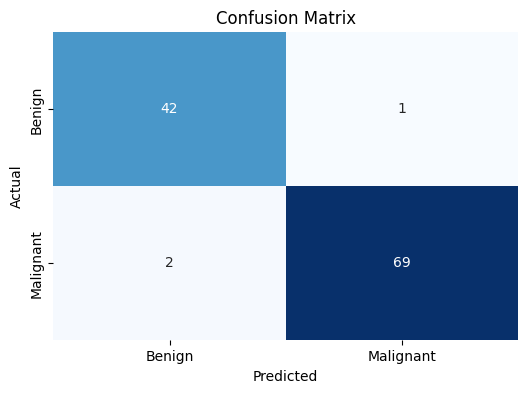

In [14]:
# confusion matrix plot
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()



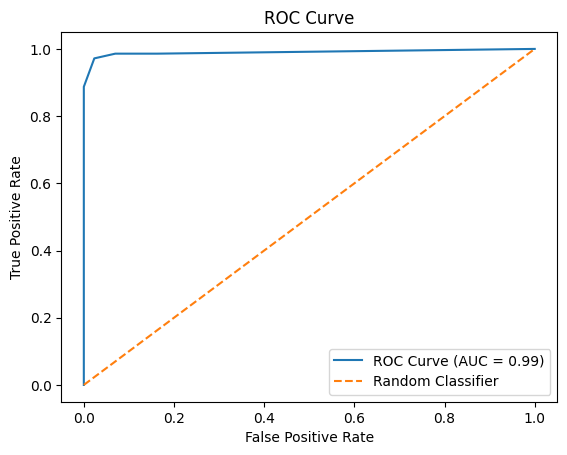

In [15]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_test, knn.predict_proba(X_test_selected)[:, 1])
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()

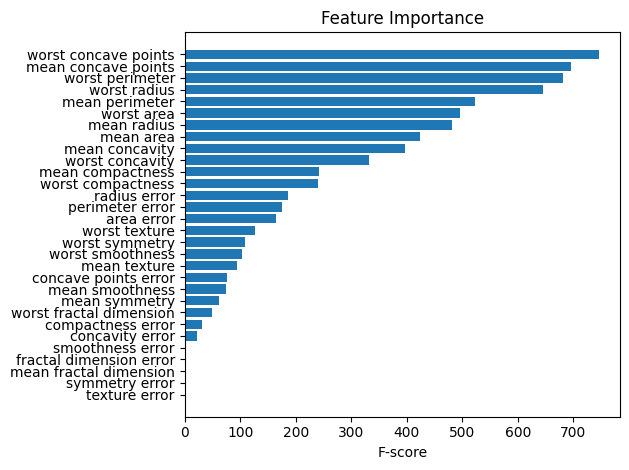

In [16]:
# Feature Importance
feature_importance = selector.scores_
sorted_idx = np.argsort(feature_importance)
pos = np.arange(sorted_idx.shape[0]) + .5
plt.barh(pos, feature_importance[sorted_idx], align='center')
plt.yticks(pos, np.array(data.feature_names)[sorted_idx])
plt.xlabel('F-score')
plt.title('Feature Importance')

plt.tight_layout()
plt.show()

In [17]:
#Results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print("\nSelected Features:")
for feature in selected_feature_names:
    print(feature)

# Cross-validation
cv_scores = cross_val_score(knn, X_train_selected, y_train, cv=5)
print(f"\nCross-validation scores: {cv_scores}")
print(f"Mean CV score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Accuracy: 0.9737
Precision: 0.9857
Recall: 0.9718
F1-Score: 0.9787
ROC-AUC: 0.9902

Selected Features:
mean radius
mean perimeter
mean area
mean concavity
mean concave points
worst radius
worst perimeter
worst area
worst concavity
worst concave points

Cross-validation scores: [0.9010989  0.93406593 0.95604396 0.94505495 0.91208791]
Mean CV score: 0.9297 (+/- 0.0408)


***Document the findings and results***

Final analsis of above findings in detail:

1. Model Performance Metrics:
   - Accuracy (0.9737): The model correctly classified 97.37% of the samples in the test set. This is an excellent accuracy, indicating strong overall performance.
   - Precision (0.9857): Out of all the samples the model predicted as positive (malignant), 98.57% were actually positive. This high precision suggests a very low false positive rate.
   - Recall (0.9718): The model correctly identified 97.18% of all actual positive samples. This high recall indicates a low false negative rate.
   - F1-Score (0.9787): This balanced measure of precision and recall is very high, confirming the model's strong performance in both aspects.
   - ROC-AUC (0.9902): This score, very close to 1, suggests that the model has an excellent ability to distinguish between benign and malignant cases.

2. Selected Features:
   The feature selection process identified these as the most important features:
   - mean radius
   - mean perimeter
   - mean area
   - mean concavity
   - mean concave points
   - worst radius
   - worst perimeter
   - worst area
   - worst concavity
   - worst concave points

   This selection suggests that both the average ("mean") and extreme ("worst") measurements of cell nuclei are important in distinguishing between benign and malignant samples. Notably, features related to size (radius, perimeter, area) and shape irregularity (concavity, concave points) seem to be particularly relevant.

3. Cross-validation scores:
   The 5-fold cross-validation scores are: [0.9010989, 0.93406593, 0.95604396, 0.94505495, 0.91208791]
   - Mean CV score: 0.9297 (+/- 0.0408)

   These scores indicate consistent performance across different subsets of the data. The mean score of 0.9297 is high, and the standard deviation (0.0408) is relatively low, suggesting that the model's performance is stable and generalizes well.

Key Insights:
1. The kNN model performs exceptionally well in classifying breast cancer cases, with high accuracy, precision, and recall.
2. The model is particularly good at avoiding false positives (high precision), which is crucial in a medical context to prevent unnecessary stress and procedures for patients.
3. The selected features highlight the importance of cell nuclei measurements, particularly size and shape irregularities, in detecting malignant cases.
4. The cross-validation results show that the model's performance is consistent and robust, with only slight variations across different data subsets.

Areas for Potential Further Investigation:
1. You might consider experimenting with different numbers of neighbors (k) to see if you can improve the model's performance further.
2. It could be interesting to compare this kNN model's performance with other algorithms like Random Forests or Support Vector Machines on the same dataset.
3. Exploring the relationships between the selected features could provide additional insights into the characteristics of malignant vs. benign tumors.

Overall, these results indicate that your kNN model is performing very well for this breast cancer classification task, providing reliable predictions with a good balance between identifying malignant cases and avoiding false alarms.



***Is it possible to use KNN for Regression? If yes, then how?***

**Yes,** it is possible to use kNN for regression tasks. The algorithm is then called k-Nearest Neighbors Regression. Here's how it works:

1. Instead of voting for the most common class among the k nearest neighbors (as in classification), kNN regression takes the average (or weighted average) of the target values of the k nearest neighbors.

2. The prediction for a new instance is the mean or median of the values of its k nearest neighbors.

3. The process for finding the nearest neighbors is the same as in classification, typically using Euclidean distance or other distance metrics.

4. The choice of k is still important and can be optimized using cross-validation.



KNN regression can be particularly useful for problems where the relationship between features and the target variable is complex or non-linear, as it doesn't make assumptions about the underlying data distribution.
